# 03 ? Manufacturers: EDA and cleaning

Consolidated from the original `sect3` notebooks. The executable pipeline lives in `src/` (`python -m src.pipeline`); these notebooks document the exploration and the cleaning decisions.


---

## Part 1 ? Preliminary EDA

# Preliminary Exploratory Data Analysis

Auto-generated overview of a CSV dataset. Drop your file in `data/raw/` and run all cells.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline
print("Libraries loaded correctly")


Libraries loaded correctly


## 1. Data Loading

Detects and loads the CSVs found in `data/raw/`.

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("manufacturers")
print(f"Loading: {file_path.name}")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")


Loading: manufacturers-1681209657.csv
Shape: 31,827 rows x 10 columns


In [3]:
df.head(10)


,id,address,comment,name,parent_company,representative,slug,source,created_at,updated_at
0,1,NaN,“We are in constant communication with regulat...,Abbot Laboratories,Abbott Laboratories,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,Abbott Medical Optics (AMO) Inc.,Johnson & Johnson,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
2,3,NaN,NaN,Alcon Laboratories Inc.,Novartis Ag,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
3,4,NaN,NaN,ANADOLU TIP TEKNO.ÜRETİM PAZ.İTH İHRTİC SAN AŞ,NaN,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
4,5,NaN,NaN,ARCHEM SAĞLIK SANAYİ TİCARET LİMİTED ŞİRKETİ,NaN,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
5,6,NaN,NaN,ARKRAY Inc.,Arkray Inc.,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
6,7,NaN,NaN,Arrow International Inc.,Teleflex Incorporated,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
7,8,NaN,NaN,Aspen Medical,"Hill-Rom Holdings, Inc",NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
8,9,NaN,NaN,B. Braun Melsungen AG,Ludwig G. Braun Gmbh U. Co. Kg,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
9,10,NaN,NaN,"Beckman Coulter, Inc.",Danaher Corporation,NaN,turkey-drugs-and-medical-devices-agency-titck-...,Turkey Drugs and Medical Devices Agency (Titck),2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


## 2. Column Overview

Data types, non-null counts, and memory usage.

In [4]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31827 entries, 0 to 31826
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              31827 non-null  int64 
 1   address         5969 non-null   object
 2   comment         2810 non-null   object
 3   name            31790 non-null  object
 4   parent_company  25866 non-null  object
 5   representative  739 non-null    object
 6   slug            31827 non-null  object
 7   source          31826 non-null  object
 8   created_at      31827 non-null  object
 9   updated_at      31827 non-null  object
dtypes: int64(1), object(9)
memory usage: 2.4+ MB
None


In [5]:
dtype_counts = df.dtypes.value_counts()
print("Column type distribution:")
for dtype, count in dtype_counts.items():
    print(f"  {dtype.name}: {count} columns")


Column type distribution:
  object: 9 columns
  int64: 1 columns


## 3. Missing Values Analysis

In [6]:
print(f"{df.isna().sum().sum()}")


91962


In [7]:
# Per-column nulls
missing_cols = pd.DataFrame({
    "Missing": df.isna().sum(),
    "%": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("Missing", ascending=False)

missing_cols = missing_cols[missing_cols["Missing"] > 0]
if missing_cols.empty:
    print("No missing values found.")
else:
    display(missing_cols)
    print(f"\nTotal missing values: {df.isna().sum().sum()}")


,Missing,%
representative,31088,97.68
comment,29017,91.17
address,25858,81.25
parent_company,5961,18.73
name,37,0.12
source,1,0.00



Total missing values: 91962


In [8]:
# Per-row null distribution
nulls_per_row = df.isna().sum(axis=1)

print("Rows with nulls:")
for threshold in [1, 2, 5, 10, 20, 50]:
    count = (nulls_per_row >= threshold).sum()
    print(f"  ≥{threshold:>3} nulls: {count:>6,} rows ({count / len(df) * 100:>5.1f}%)")

print(f"\nNulls per row — distribution:")
dist = nulls_per_row.value_counts().sort_index()
display(dist.head(20).to_frame("# rows"))


Rows with nulls:


  ≥  1 nulls: 31,827 rows (100.0%)
  ≥  2 nulls: 31,404 rows ( 98.7%)
  ≥  5 nulls:     23 rows (  0.1%)
  ≥ 10 nulls:      0 rows (  0.0%)
  ≥ 20 nulls:      0 rows (  0.0%)
  ≥ 50 nulls:      0 rows (  0.0%)

Nulls per row — distribution:


,# rows
1,423
2,6222
3,21656
4,3503
5,23


In [9]:
# Column drop recommendations (>40% nulls)
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "Null %": null_pct.round(2),
    "Recommendation": null_pct.apply(
        lambda p: "DROP (>40%)" if p > 40 else "KEEP"
    )
}).sort_values("Null %", ascending=False)

to_drop = rec_df[rec_df["Recommendation"] == "DROP (>40%)"]
if not to_drop.empty:
    print("=" * 55)
    print(f"  {len(to_drop)} column(s) with >40% nulls — recommended for removal")
    print("=" * 55)
    display(to_drop)
else:
    print("No columns exceed 40% nulls — none recommended for removal.")


  3 column(s) with >40% nulls — recommended for removal


,Null %,Recommendation
representative,97.68,DROP (>40%)
comment,91.17,DROP (>40%)
address,81.25,DROP (>40%)


## 4. Numerical Columns – Descriptive Statistics

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical / text columns ({len(cat_cols)}): {cat_cols}")


Numerical columns (1): ['id']
Categorical / text columns (9): ['address', 'comment', 'name', 'parent_company', 'representative', 'slug', 'source', 'created_at', 'updated_at']


In [11]:
if num_cols:
    display(df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
id,31827.0,15914.0,9187.807845,1.0,319.26,1592.3,7957.5,15914.0,23870.5,30235.7,31508.74,31827.0


## 5. Categorical Columns – Value Counts

In [12]:
for col in cat_cols[:10]:
    vc = df[col].value_counts(dropna=False).head(15)
    print(f"\n--- {col} ({vc.sum():,} non-null / {df[col].nunique():,} unique) ---")
    print(vc.to_string())



--- address (26,251 non-null / 5,045 unique) ---
address
NaN             25858
MISSISSAUGA       114
MARKHAM            39
TORONTO            39
MONTREAL           31
OAKVILLE           26
BURLINGTON         25
Seoul, Korea       20
LAVAL              16
SAN DIEGO          16
U.S.A.             15
CONCORD            15
QUEBEC             13
OTTAWA             12
WINNIPEG           12

--- comment (31,825 non-null / 16 unique) ---
comment
NaN                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

## 6. Outlier Detection (IQR method)

In [13]:
if num_cols:
    outlier_data = []
    for col in num_cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower) | (df[col] > upper)][col].dropna()
        if len(outliers) > 0:
            outlier_data.append({
                "Column": col,
                "Outliers": len(outliers),
                "%": round(len(outliers) / df[col].notna().sum() * 100, 2),
                "Lower bound": round(lower, 2),
                "Upper bound": round(upper, 2)
            })
    if outlier_data:
        outlier_df = pd.DataFrame(outlier_data).sort_values("Outliers", ascending=False)
        display(outlier_df)
    else:
        print("No outliers detected via IQR.")


No outliers detected via IQR.


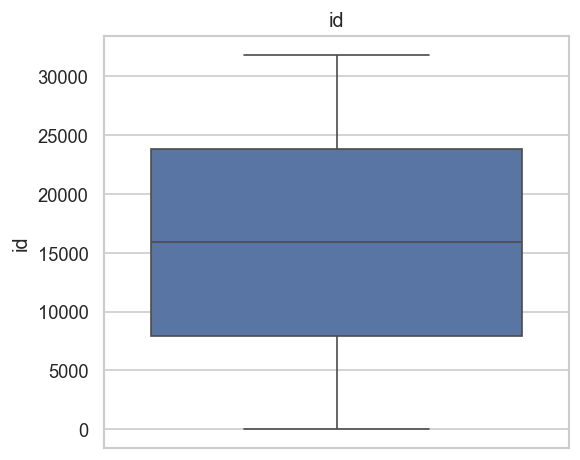

In [14]:
if num_cols:
    n_cols = min(6, len(num_cols))
    fig, axes = plt.subplots(1, n_cols, figsize=(5 * n_cols, 4))
    if n_cols == 1:
        axes = [axes]
    for ax, col in zip(axes, num_cols[:n_cols]):
        sns.boxplot(y=df[col], ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()


## 7. Correlation Analysis

In [15]:
if len(num_cols) >= 2:
    corr = df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 20,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_unstacked = corr.unstack()
    corr_unstacked = corr_unstacked[
        corr_unstacked.index.get_level_values(0) !=
        corr_unstacked.index.get_level_values(1)
    ]
    top_corr = corr_unstacked.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (col1, col2), val in top_corr.items():
        print(f"  {col1}  –  {col2}: {corr.loc[col1, col2]:+.4f}")


## 8. Distribution of Numerical Columns

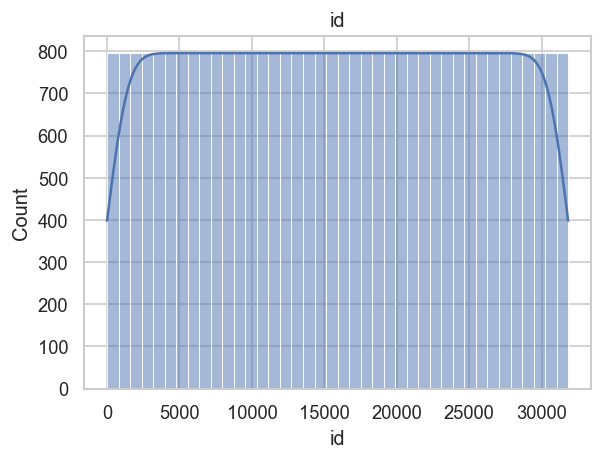

In [16]:
if num_cols:
    n_hist = min(9, len(num_cols))
    n_rows = (n_hist + 2) // 3
    fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
    axes = axes.flatten()
    for ax, col in zip(axes, num_cols[:n_hist]):
        sns.histplot(df[col].dropna(), kde=True, bins=40, ax=ax)
        ax.set_title(col)
    for ax in axes[n_hist:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()


## 9. Summary

In [17]:
rows_with_nulls = (df.isna().sum(axis=1) >= 1).sum()
cols_to_drop = (df.isna().mean() * 100 > 40).sum()

print("=" * 60)
print("PRELIMINARY EDA SUMMARY")
print("=" * 60)

print(f"\nDataset: {file_path.name}")
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print(f"Missing cells: {df.isna().sum().sum():,} / {df.size:,} ({df.isna().sum().sum() / df.size * 100:.2f}%)")
print(f"Rows with ≥1 null: {rows_with_nulls:,} ({rows_with_nulls / len(df) * 100:.1f}%)")
print(f"Columns with >40% nulls (recommended for removal): {cols_to_drop}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Numerical columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")


PRELIMINARY EDA SUMMARY

Dataset: manufacturers-1681209657.csv
Dimensions: 31,827 rows x 10 columns
Missing cells: 91,962 / 318,270 (28.89%)
Rows with ≥1 null: 31,827 (100.0%)
Columns with >40% nulls (recommended for removal): 3
Duplicate rows: 0
Numerical columns: 1
Categorical columns: 9
Memory usage: 22.94 MB


---

## Part 2 ? Formal EDA

# 01. Formal Exploratory Data Analysis

Structured deep-dive into the dataset. Builds on the preliminary EDA with richer diagnostics.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("manufacturers")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Loaded: {file_path.name}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print("Working with Manufacturers CSV")


Loaded: manufacturers-1681209657.csv
Shape: 31,827 rows x 10 columns
Working with Manufacturers CSV


## 1. Schema Audit

Complete column-by-column diagnostic: type, nulls, cardinality, memory.

In [3]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "cardinality": df.nunique(dropna=False),
    "memory_kb": (df.memory_usage(deep=True) / 1024).round(1)
})
display(schema)
print(f"Total memory: {schema['memory_kb'].sum():,.1f} KB")

,dtype,non_null,null_pct,cardinality,memory_kb
Index,NaN,NaN,NaN,NaN,0.1
address,object,5969.0,81.25,5046.0,1402.9
comment,object,2810.0,91.17,17.0,4929.9
created_at,object,31827.0,0.00,6558.0,2237.8
id,int64,31827.0,0.00,31827.0,248.6
name,object,31790.0,0.12,20173.0,2285.6
parent_company,object,25866.0,18.73,3502.0,1929.3
representative,object,739.0,97.68,391.0,1028.8
slug,object,31827.0,0.00,31827.0,4015.4
source,object,31826.0,0.00,47.0,3177.8


Total memory: 23,494.0 KB


In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical: {len(num_cols)}  |  Categorical: {len(cat_cols)}")

Numerical: 1  |  Categorical: 9


## 2. Missing Values - Full Diagnosis

In [5]:
missing_cols = schema[schema["null_pct"] > 0][["null_pct"]].sort_values("null_pct", ascending=False)
if not missing_cols.empty:
    display(missing_cols)
else:
    print("No missing values.")

,null_pct
representative,97.68
comment,91.17
address,81.25
parent_company,18.73
name,0.12


Rows with >=X nulls:
  >=  1: 31,827 (100.0%)
  >=  2: 31,404 ( 98.7%)
  >=  5:     23 (  0.1%)
  >= 10:      0 (  0.0%)
  >= 20:      0 (  0.0%)
  >= 50:      0 (  0.0%)


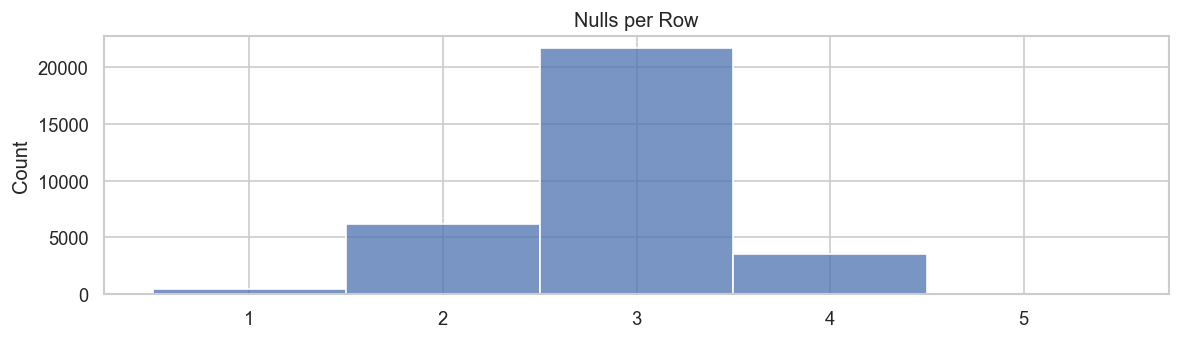

In [6]:
nulls_per_row = df.isna().sum(axis=1)
print("Rows with >=X nulls:")
for t in [1, 2, 5, 10, 20, 50]:
    n = (nulls_per_row >= t).sum()
    print(f"  >={t:>3}: {n:>6,} ({n/len(df)*100:>5.1f}%)")

if nulls_per_row.max() > 0:
    plt.figure(figsize=(10, 3))
    sns.histplot(nulls_per_row, bins=min(50, nulls_per_row.max()+1), discrete=True)
    plt.title("Nulls per Row")
    plt.tight_layout()
    plt.show()

In [7]:
null_pct = df.isna().mean() * 100
rec_df = pd.DataFrame({
    "null_pct": null_pct.round(2),
    "decision": null_pct.apply(lambda p: "DROP (>40%)" if p > 40 else "KEEP")
}).sort_values("null_pct", ascending=False)

to_drop = rec_df[rec_df["decision"] == "DROP (>40%)"]
n_drop = len(to_drop)
print(f"Columns recommended for removal (null >40%): {n_drop}")
if n_drop:
    display(to_drop)

Columns recommended for removal (null >40%): 3


,null_pct,decision
representative,97.68,DROP (>40%)
comment,91.17,DROP (>40%)
address,81.25,DROP (>40%)


## 3. Numerical Analysis

In [8]:
if num_cols:
    stats = df[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
    stats["skew"] = df[num_cols].skew().round(3)
    stats["kurtosis"] = df[num_cols].kurtosis().round(3)
    display(stats)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis
id,31827.0,15914.0,9187.807845,1.0,319.26,1592.3,7957.5,15914.0,23870.5,30235.7,31508.74,31827.0,0.0,-1.2


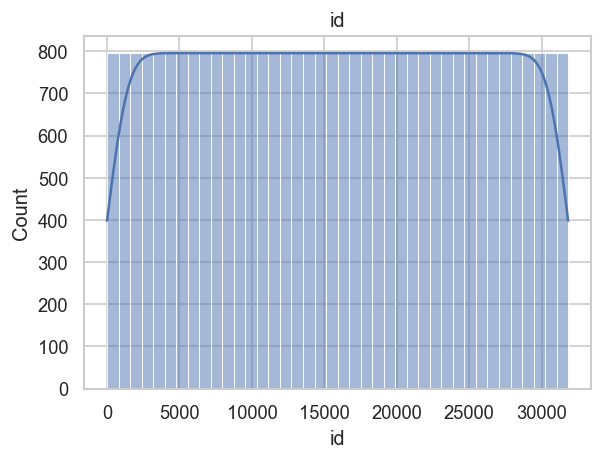

In [9]:
if num_cols:
    n_hist = min(9, len(num_cols))
    rows = (n_hist + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(14, 4 * rows))
    axes = axes.flatten()
    for ax, col in zip(axes, num_cols[:n_hist]):
        sns.histplot(df[col].dropna(), kde=True, bins=40, ax=ax)
        ax.set_title(col)
    for ax in axes[n_hist:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

## 4. Categorical Analysis

In [10]:
if cat_cols:
    cat_summary = pd.DataFrame({
        "unique": df[cat_cols].nunique(),
        "top_val": [df[c].value_counts(dropna=False).index[0] if df[c].nunique() > 0 else None for c in cat_cols],
        "top_pct": [round(df[c].value_counts(dropna=False).iloc[0] / len(df) * 100, 1) for c in cat_cols]
    })
    display(cat_summary)

,unique,top_val,top_pct
address,5045,NaN,81.2
comment,16,NaN,91.2
name,20172,NaN,0.1
parent_company,3501,NaN,18.7
representative,390,NaN,97.7
slug,31827,turkey-drugs-and-medical-devices-agency-titck-...,0.0
source,46,U.S. Food and Drug Administration,12.4
created_at,6558,2022-08-04 08:28:02 UTC,0.2
updated_at,6558,2022-08-04 08:28:02 UTC,0.2


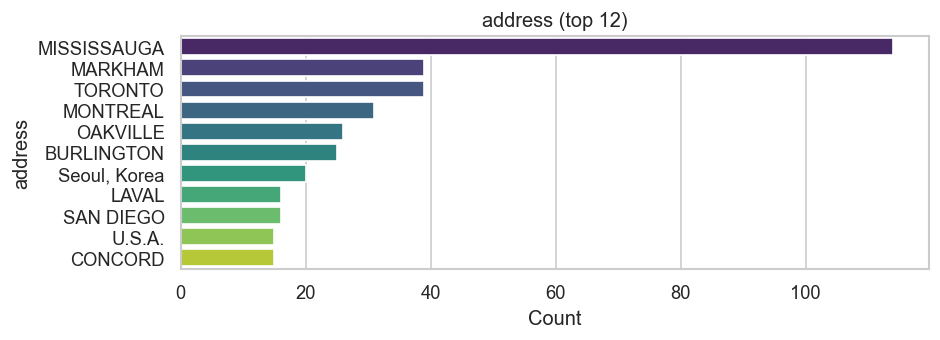

C:\Users\arizo\AppData\Local\Temp\ipykernel_516\3430780275.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


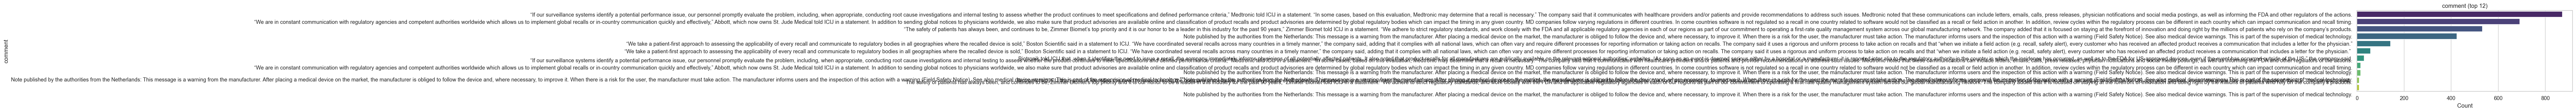

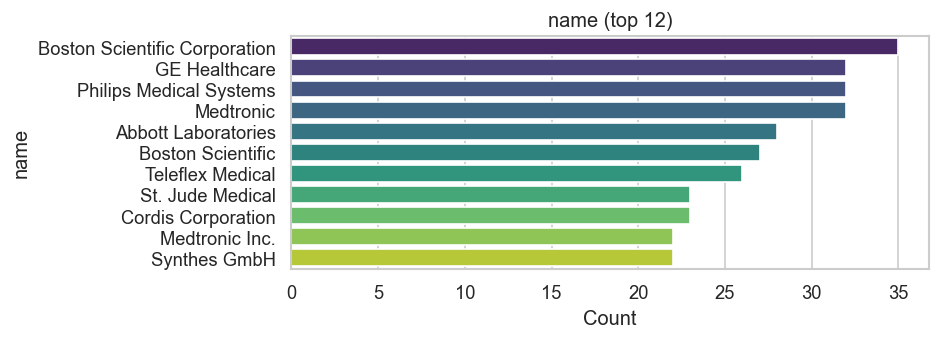

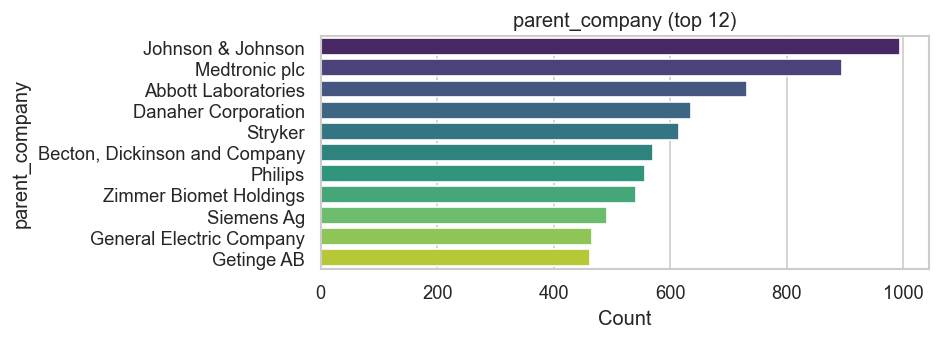

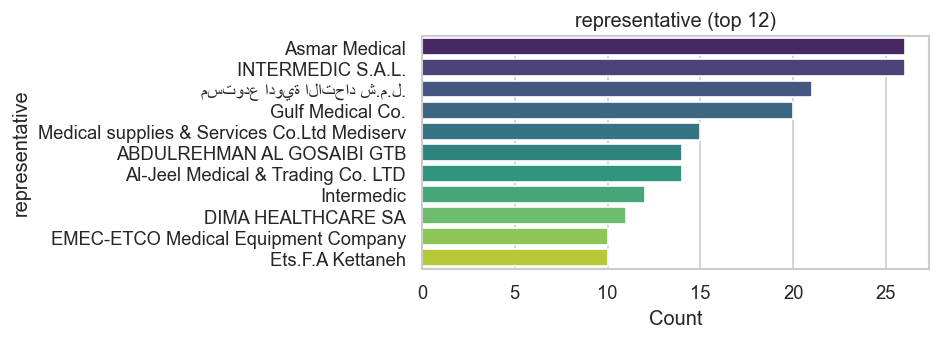

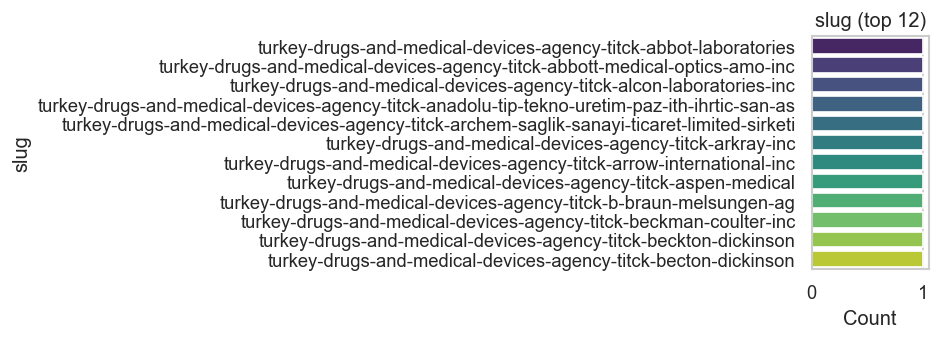

In [11]:
for col in cat_cols[:6]:
    vc = df[col].value_counts(dropna=False).head(12)
    plt.figure(figsize=(8, 3))
    sns.barplot(x=vc.values, y=vc.index, hue=vc.index, palette="viridis", legend=False)
    plt.title(f"{col} (top 12)")
    plt.xlabel("Count")
    plt.tight_layout()
    plt.show()

## 5. Correlation Analysis

In [12]:
if len(num_cols) >= 2:
    corr = df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    plt.figure(figsize=(max(8, len(num_cols) * 0.6), max(6, len(num_cols) * 0.5)))
    sns.heatmap(corr, mask=mask, annot=len(num_cols) <= 15,
                fmt=".2f", cmap="RdBu_r", center=0,
                square=True, linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

    corr_u = corr.unstack()
    corr_u = corr_u[corr_u.index.get_level_values(0) != corr_u.index.get_level_values(1)]
    top = corr_u.abs().sort_values(ascending=False).drop_duplicates().head(10)
    print("Top 10 strongest correlations:")
    for (c1, c2), v in top.items():
        print(f"  {c1:25s} vs {c2:25s}: {corr.loc[c1, c2]:+.4f}")

## 6. Outlier Analysis

In [13]:
if num_cols:
    rows = []
    for col in num_cols:
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        out = df[(df[col] < low) | (df[col] > high)][col].dropna()
        if len(out):
            rows.append({"col": col, "n": len(out), "%": round(len(out)/df[col].notna().sum()*100, 2)})
    out_df = pd.DataFrame(rows).sort_values("n", ascending=False) if rows else pd.DataFrame(columns=["col", "n", "%"])
    if not out_df.empty:
        display(out_df)
    else:
        print("No outliers detected.")
else:
    out_df = pd.DataFrame()

No outliers detected.


## 7. Summary & Recommendations

In [14]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)
print(f"  Dataset:                {file_path.name}")
print(f"  Dimensions:             {df.shape[0]:>8,} rows x {df.shape[1]:,} cols")
print(f"  Missing cells:          {df.isna().sum().sum():>8,} ({df.isna().sum().sum()/df.size*100:.2f}%)")
print(f"  Rows with nulls:        {(df.isna().sum(axis=1)>=1).sum():>8,}")
print(f"  Duplicate rows:         {df.duplicated().sum():>8,}")
print(f"  Memory:                 {df.memory_usage(deep=True).sum()/1024**2:.2f} MB")
print(f"  Num cols:               {len(num_cols):>8}")
print(f"  Cat cols:               {len(cat_cols):>8}")
print(f"  Cols to drop (>40%):    {n_drop:>8}")
if num_cols:
    print(f"  Outlier cols:           {len(out_df):>8}")

EDA SUMMARY
  Dataset:                manufacturers-1681209657.csv
  Dimensions:               31,827 rows x 10 cols
  Missing cells:            91,962 (28.89%)
  Rows with nulls:          31,827
  Duplicate rows:                0
  Memory:                 24.73 MB
  Num cols:                      1
  Cat cols:                      9
  Cols to drop (>40%):           3
  Outlier cols:                  0


---

## Part 3 ? Pre-cleaning

# 02. Data Pre-Cleaning - `manufacturers`

Convierte `manufacturers` en `data/processed/manufacturersProcessed.csv`, la tabla de dimensiones de
fabricantes que usa el pipeline del dashboard.

Reglas aplicadas:

1. Columnas con **>40% de nulos** → fuera (`address`, `comment`, `representative`).
2. `updated_at` es idéntica a `created_at` en el 100% de las filas → fuera.
3. Se eliminan las filas sin `name` (37 filas, 0,12%).
4. Limpieza de strings, optimización a `category`, deduplicado y guardado.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube desde el cwd hasta encontrar la raiz del proyecto (requirements.txt + data/)."""
    for p in (start, *start.parents):
        if (p / "requirements.txt").exists() and (p / "data").exists():
            return p
    raise FileNotFoundError(f"No se encontro la raiz del proyecto desde {start}")

ROOT = find_project_root()
raw_dir = ROOT / "data" / "raw"
proc_dir = ROOT / "data" / "processed"
proc_dir.mkdir(parents=True, exist_ok=True)

def find_raw_csv(prefix: str) -> Path:
    """Localiza el CSV crudo por prefijo: 'devices', 'events' o 'manufacturers'."""
    matches = sorted(raw_dir.glob(f"{prefix}-*.csv"))
    if not matches:
        raise FileNotFoundError(f"No hay CSV que empiece por '{prefix}-' en {raw_dir}")
    if len(matches) > 1:
        print(f"AVISO: {len(matches)} archivos con prefijo '{prefix}-', se usa {matches[0].name}")
    return matches[0]

file_path = find_raw_csv("manufacturers")
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
n_row0, n_col0 = df.shape
print(f"Loaded: {file_path.name}  ({n_row0:,} rows x {n_col0:,} cols)")

Loaded: manufacturers-1681209657.csv  (31,827 rows x 10 cols)


## 1. Columnas con >40% de nulos

| Columna | % nulos | Decisión |
| :--- | ---: | :--- |
| `representative` | 97.68 | DROP |
| `comment` | 91.17 | DROP |
| `address` | 81.25 | DROP |
| `parent_company` | 18.73 | KEEP |
| `name` | 0.12 | KEEP (se eliminan sus 37 filas vacías) |
| `id`, `slug`, `source`, `created_at`, `updated_at` | 0.00 | KEEP |

In [2]:
null_pct = (df.isna().mean() * 100).round(2)
high_null_cols = null_pct[null_pct > 40].index.tolist()
df.drop(columns=high_null_cols, inplace=True)
print(f"Dropped {len(high_null_cols)} column(s) with >40% nulls: {high_null_cols}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

Dropped 3 column(s) with >40% nulls: ['address', 'comment', 'representative']
Shape: 31,827 rows x 7 columns


## 2. Drop `updated_at`

La columna es idéntica a `created_at` en el 100% de las filas (comprobado en el EDA formal).

In [3]:
match_pct = (df["created_at"] == df["updated_at"]).mean()
print(f"created_at == updated_at: {match_pct:.1%} match")
df.drop(columns=["updated_at"], inplace=True)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

created_at == updated_at: 100.0% match
Shape: 31,827 rows x 6 columns


## 3. Filas sin `name`

`name` es la clave visible de la dimensión: se descartan las 37 filas que no lo traen.

In [4]:
n_before = len(df)
df.dropna(subset=["name"], inplace=True)
n_no_name = n_before - len(df)
print(f"Removed {n_no_name:,} row(s) without name  ->  {len(df):,} rows")

Removed 37 row(s) without name  ->  31,790 rows


## 4. String cleaning

In [5]:
str_cols = df.select_dtypes(include=["object"]).columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip().replace("nan", None)
print(f"Cleaned {len(str_cols)} string column(s)")

cat_opt = []
for col in df.select_dtypes(include=["object"]).columns:
    if df[col].nunique() / len(df) < 0.05:
        df[col] = df[col].astype("category")
        cat_opt.append(col)
print(f"Optimized to category: {cat_opt}")

Cleaned 5 string column(s)
Optimized to category: ['source']


## 5. Deduplicate rows

In [6]:
n_dupes = 0
n_before = len(df)
df.drop_duplicates(inplace=True)
n_dupes = n_before - len(df)
print(f"Removed {n_dupes:,} duplicate row(s) ({n_dupes/n_before*100:.2f}%)")

Removed 0 duplicate row(s) (0.00%)


## 6. Save pre-cleaned data

In [7]:
out_path = proc_dir / "manufacturersProcessed.csv"
df.to_csv(out_path, index=False, encoding="utf-8")
print(f"Saved: {out_path}  ({df.shape[0]:,} rows x {df.shape[1]:,} columns)")

Saved: D:\projects\dataScienceProjects\medicalSupply\data\processed\manufacturersProcessed.csv  (31,790 rows x 6 columns)


## 7. Pre-cleaning Report

In [8]:
n_row1, n_col1 = df.shape
print("=" * 55)
print("  PRE-CLEANING REPORT (manufacturers)")
print("=" * 55)
print(f"  Original shape:           {n_row0:>8,} rows x {n_col0:,} cols")
print(f"  Final shape:              {n_row1:>8,} rows x {n_col1:,} cols")
print(f"  Rows removed (no name):   {n_no_name:>8,}")
print(f"  Columns dropped:          {n_col0 - n_col1:>8}")
print(f"    - High null (>40%):     {len(high_null_cols):>8}")
print(f"    - updated_at:           {1:>8}")
print(f"  Duplicates removed:       {n_dupes:>8}")
print(f"  Optimized to category:    {len(cat_opt):>8}")
print(f"  Remaining missing:        {df.isna().sum().sum():>8,}")
print()
print("Missing by column:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

  PRE-CLEANING REPORT (manufacturers)
  Original shape:             31,827 rows x 10 cols
  Final shape:                31,790 rows x 6 cols
  Rows removed (no name):         37
  Columns dropped:                 4
    - High null (>40%):            3
    - updated_at:                  1
  Duplicates removed:              0
  Optimized to category:           1
  Remaining missing:           5,937

Missing by column:


parent_company    5936
source               1